# Inheritance, super() & Method Resolution Order

**OOP theory + practice notes on inheritance.** Reusing a parent class from a
child, the three inheritance types, constructors inside inheritance, `super()`, MRO — then
hands-on practice with `Car`/`ElectricCar` and `User` classes.

**What you will learn**
- `class Child(Parent):` — reusing attributes & methods
- Single, multi-level and multiple inheritance
- Which `__init__` runs when a child is created
- `super()` to reach the parent's version of a method
- MRO: with two parents, Python resolves **left to right**

## Inheritance — reusing code through an "is-a" relationship

- A class can be built **upon another class**: the child inherits all its attributes and methods.
- Benefits: reuse, less duplication, easy extension.
- The diagrams show parent → child flow (single, multi-level, multiple).


    In object-oriented programming, inheritance is the mechanism of basing an object or class upon another object (prototype-based inheritance) or class (class-based inheritance), retaining similar implementation. ... An inherited class is called a subclass of its parent class or super class.


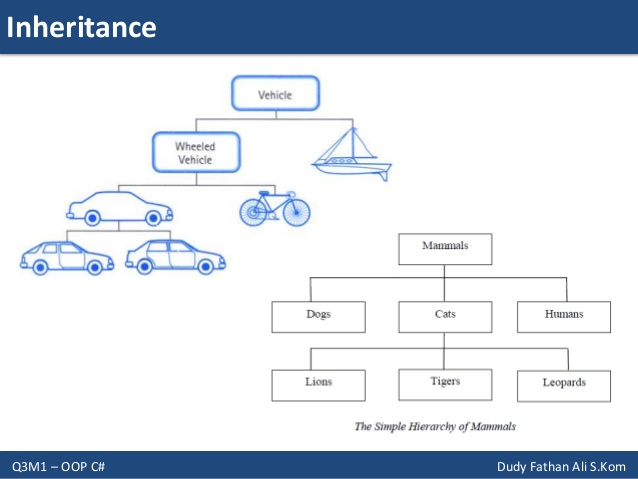

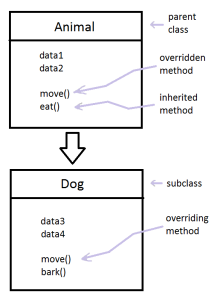

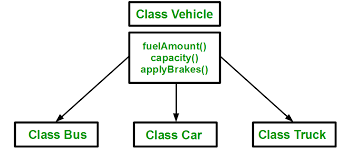

## Inheritance in Python

- Syntax: `class Child(Parent):` — just pass the parent class name in the brackets.
- The child object can call **both** its own methods and every public parent method.

In [ ]:
# parent class A: two features, no inheritance yet
# Define a class A with two functions
class A:
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")
a1=A()
a1.feature1()
a1.feature2()

In [ ]:
# Define another class with two functions
class B():
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")

b1 = B()
b1.feature3()
b1.feature4()

Now if there is a relation of is-a between class A and class B. Class B can inherit class A

In [ ]:
# class B(A) — B now owns every public feature of A as well
class B(A):# Just by passing class name of parent class
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")
# class was accessing only class B functions
# Now class B inherits class A, it can access all the
# attributes and behaviours of class A

In [ ]:
# b2 can call feature1/feature2 (from A) and feature3/feature4 (from B)
b2 = B()

b2.feature3()
b2.feature4()
b2.feature1()
b2.feature2()

## Multi-level inheritance

- A chain: `C` inherits `B`, `B` inherits `A` → `C` gets features of **both**, directly and indirectly.

In [ ]:
# C(B): direct parent B, indirect grandparent A — gets all six features
# Define a class C that inherits class B directly
# and inherits class A indirectly
# Class C will have access to features of class A also

class C(B):
    def feature5(self):
        print("Feature5 is working")
    def feature6(self):
        print("Feature6 is working")
c1 = C()

c1.feature1() 
c1.feature2() 
c1.feature3() 
c1.feature4() 
c1.feature5() 
c1.feature6() 
        

## Multiple inheritance

- One child, two parents: `class C(A, B):` → the child object can use features of A **and** B.
- If both parents define the same name, Python resolves **left to right** (MRO, later below).

In [ ]:
# Define a class A with two functions
class A:
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")


In [ ]:
class B():
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")


In [ ]:
# C(A, B) — multiple inheritance: both parents merged into one child
##########################
# Inheritance
##########################

class C(A,B):
    def feature5(self):
        print("Feature5 is working")
    def feature6(self):
        print("Feature6 is working")
# Now class C inherits class A and class B
# Now remember there is no relationship now between
# directly

In [ ]:
c11 = C()

In [ ]:
c11.feature1()
c11.feature2()
c11.feature3()
c11.feature4()
c11.feature5()
c11.feature6()


## Constructors during inheritance

- Child has **no** `__init__` → the parent's constructor runs automatically.
- Child **defines** `__init__` → only the child's runs; call `super().__init__()` to also
  initialise the parent's part.

In [ ]:
# parent constructor runs automatically when the child has none
class A:    
    def __init__(self):
        print("init of class A works")
    
    def feature1(self):
        print("Feature1 is working")
    
    def feature2(self):
        print("Feature2 is working")

In [ ]:
class B(A):
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")
a=A()
b=B()

In [ ]:
class B(A):   
    def __init__(self):
        print("Init of class B works")
    
    def feature3(self):
        print("Feature3 is working")
    
    def feature4(self):
        print("Feature4 is working")
bb = B()

## super() — reaching the parent from the child

- `super().__init__()` calls the parent constructor inside the child's constructor.
- With **two** parents, `super()` follows the MRO (left to right) — so the *left* parent's
  `__init__` is the one that runs.

super keyword is used to access the features of parent class in child class in case both have same features.
when object of child class will be  created, init of child class will work.If child had no init we have seen it will call init of parent. 
But now in above example both parent and child have init method. What if we want to access both init methods. we will use super for init of parent class

In [ ]:
# super().__init__() runs the PARENT constructor first, then the child code
class B(A):   
    def __init__(self):        
        super().__init__()
        print("Init of class B works")
    
    def feature3(self):
        print("Feature3 is working")
    
    def feature4(self):
        print("Feature4 is working")
bb = B()

What if we have two parent class(Multiple inheritance)? Which class's super will be called?
It works from left to right class

In [ ]:
class A:    
    def __init__(self):
        print("init of class A works")
    
    def feature1(self):
        print("Feature1 is working")
    
    def feature2(self):
        print("Feature2 is working")

In [ ]:
class B():   
    def __init__(self):       
        print("Init of class B works")
    
    def feature3(self):
        print("Feature3 is working")
    
    def feature4(self):
        print("Feature4 is working")

In [ ]:
# C(B, A): MRO gives the LEFT parent (B) priority on conflicts
# method resolution order (mro)
# priority

class C(B,A):
    def __init__(self):
        print("in C init")
        super().__init__()
    
        
c = C()    

The same thing applies to other methods of same name in both parent classes

---

## Practice: Car, ElectricCar & User classes

In [ ]:
# practice: Car with getter/setter and descriptive name
class Car(): 
    def __init__(self, make, model, year):    
        self.make = make
        self.model = model
        self.year = year

    def get_descriptive_name(self):        
        long_name = str(self.year) + ' ' + self.make + ' ' + self.model
        return long_name.title()

In [ ]:
my_new_car = Car('audi', 'a4', 2016)
print(my_new_car.get_descriptive_name())

In [ ]:
class Car(): 
    def __init__(self, make, model, year):    
        self.make = make
        self.model = model
        self.year = year
        self._odometer_reading = 0
    def get_descriptive_name(self):        
         long_name = f"{self.year} {self.make} {self.model}"
         return long_name.title()  

    def get_odometer(self):       
        print(f"This car has{self._odometer_reading} miles on it.")
    
    def set_odometer(self, mileage):
        if mileage>self._odometer_reading:
            self._odometer_reading = mileage
        else:
            return "you can not roll back odometer"
    def increment_odometer(self, miles): 
        self._odometer_reading += miles

In [ ]:
my_new_car = Car('audi', 'a4', 2016)
print(my_new_car.get_descriptive_name())
my_new_car.get_odometer()

In [ ]:
my_new_car._odometer_reading = 23
my_new_car.get_odometer()

In [ ]:
my_new_car.set_odometer(50)

In [ ]:
my_new_car.get_odometer()

In [ ]:
my_new_car.set_odometer(45)

In [ ]:
my_new_car.set_odometer(145)

In [ ]:
my_new_car.get_odometer()

In [ ]:
my_new_car.get_odometer()

In [ ]:
my_new_car.increment_odometer(55)

In [ ]:
my_new_car.get_odometer()

In [ ]:
# ElectricCar(Car) + super().__init__() reuses the Car constructor
class ElectricCar(Car):
    def __init__(self, make, model, year,color, horse_power):
        super().__init__(make,model,year)
        self.color = color
        self.horse_power = horse_power
        self.battery = 100

In [ ]:
ec1 = ElectricCar('BYD', 'ATTO3', 2026, 'Black', 2000)

9-3. Users: Make a class called User. Create two attributes called first_name
and last_name, and then create several other attributes that are typically stored 
in a user profile. Make a method called describe_user() that prints a summary 
of the user’s information. Make another method called greet_user() that prints 
a personalized greeting to the user.
Create several instances representing different users, and call both methods 
for each user.

In [ ]:
# exercise 9-3: plain class with identity attributes
class User:
    def __init__(self, firstname, lastname,userid):
        self.firstname = firstname
        self.lastname = lastname
        self.userid = userid
    def describe_user(self):
        return f"{self.firstname} {self.lastname} {self.userid}"
    def greet_user(self):
        return f"Welcome {firstname} {lastname} to our learning portal!"

In [ ]:
user1 = User('nasir', 'hussain', 'nhussain')

In [ ]:
user2 = User('usman', 'shah', 'shahg')

9-5. Login Attempts: Add an attribute called login_attempts to your User
class from Exercise 9-3 (page 166). Write a method called increment_
login_attempts() that increments the value of login_attempts by 1. Write 
another method called reset_login_attempts() that resets the value of login_
attempts to 0.
Make an instance of the User class and call increment_login_attempts()
several times. Print the value of login_attempts to make sure it was incremented 
properly, and then call reset_login_attempts(). Print login_attempts again to 
make sure it was reset to 0.

In [ ]:
# exercise 9-5: add a counter attribute and an increment method
class User:
    def __init__(self, firstname, lastname,userid):
        self.firstname = firstname
        self.lastname = lastname
        self.userid = userid
        self.login_attempts = 0
    def describe_user(self):
        return f"{self.firstname} {self.lastname} {self.userid}"
    def greet_user(self):
        return f"Welcome {self.firstname} {self.lastname} to our learning portal!"
    def increment_login_attempts(self):
        self.login_attempts+=1
        return self.login_attempts
    def reset_login_attempts(self):
        self.login_attempts = 0
        return f"login attempts reset to {self.login_attempts}"
        

In [ ]:
user1 = User('nasir', 'hussain', 'nhussain')

In [ ]:
user1.login_attempts

In [ ]:
user1.increment_login_attempts()

In [ ]:
user1.increment_login_attempts()

In [ ]:
user1.increment_login_attempts()

---

## Extra practice: inheritance types, constructors & MRO

## Inheritance — quick recap set

Same three types again as compact code drills: single → multilevel → multiple,
followed by constructors and MRO.

In [ ]:
class A:
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")
        
        

a1 = A()
a1.feature1()
a1.feature2()

### Single inheritance — `class B(A)`

In [ ]:
# single inheritance drill: B(A) with two extra features
class B(A):
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")
b1 = B()
b1.feature3()
b1.feature4()
b1.feature1()
b1.feature2()

#### Multilevel inheritance — `class C(B)` where `B(A)`

In [ ]:
# multilevel drill: C(B) — B already inherits A
class C(B):
    def feature5(self):
        print("Feature5 is working")
    def feature6(self):
        print("Feature6 is working")
c1 = C()
c1.feature1()
c1.feature2()
c1.feature3()
c1.feature4()
c1.feature5()
c1.feature6()

## Multiple inheritance — `class C(A, B)`

In [ ]:
class A:
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")
        
        

a1 = A()
a1.feature1()
a1.feature2()

In [ ]:
class B():
    def feature3(self):
        print("Feature3 is working")
    def feature4(self):
        print("Feature4 is working")
b1 = B()
b1.feature3()
b1.feature4()


In [ ]:
# multiple drill: C(A, B) merges both feature sets
class C(A,B):
    def feature5(self):
        print("Feature5 is working")
c1 = C()
c1.feature1()
c1.feature2()
c1.feature3()
c1.feature4()
c1.feature5()

## Constructors in inheritance & Method Resolution Order (MRO)

- Several `__init__` combos: parent-only, child-only, both with `super()`.
- **MRO:** with two parents, resolution runs **left to right** —
  `class C(B, A)` uses B's `show()`, `class C(A, B)` uses A's `show()`.

In [ ]:
class A:
    
    def __init__(self):
        print("In init of A")
        
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")

class B(A):
    
    def feature3(self):
        print("Feature3 is working")
        
    def feature4(self):
        print("Feature4 is working")
a1=A()
b1=B()

# constructor of A will be called even if we are creating
# constructor

In [ ]:
class A:
    
    def __init__(self):
        print("In init of A")
        
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")

class B(A):
    def __init__(self):
        print("In init of B")
       
    
    def feature3(self):
        print("Feature3 is working")
        
    def feature4(self):
        print("Feature4 is working")
a1=A()
b1=B()

# constructor of B will be called now as object of B is created

In [ ]:
class A:
    
    def __init__(self):
        print("In init of A")
        
    def feature1(self):
        print("Feature1 is working")
    def feature2(self):
        print("Feature2 is working")

class B(A):
    def __init__(self):
        print("In init of B")
        super().__init__()
    
    def feature3(self):
        print("Feature3 is working")
        
    def feature4(self):
        print("Feature4 is working")
a1=A()
b1=B()

# if we want to call the init of A when object of B 
#is creating we will use super()

In [ ]:
class A:    
    def __init__(self):
        print("In init of A")
        
    def feature1(self):
        print("Feature1 is working")
        
    def feature2(self):
        print("Feature2 is working")
    def show(self):
        print("I am showing class A")

In [ ]:
class B():
    def __init__(self):
        print("in init of B")
       
    
    def feature3(self):
        print("Feature3 is working")
        
    def feature4(self):
        print("Feature4 is working")

    def show(self):
        print("I am showing class B")

In [ ]:
# C(B, A) with super() — B (left) wins the MRO race
class C(A,B):
    def __init__(self):
        print("init of C")
        super().__init__()
        # now we have two parent classes super will call init of???
        # There is a term called MRO
        # Method resolution is from Left to Right
        # init of A will be called 
c  = C()

In [ ]:
# show() of class A will be called (MRO)
c.show()

In [ ]:
class C(B,A):
    def __init__(self):
        print("init of C")
        super().__init__()
        # now we have two parent classes super will call init of???
        # There is a term called MRO
        # Method resolution is from Left to Right
        # init of A will be called 
c  = C()

In [ ]:
# show() of class B will be called (MRO)
c.show()

In [ ]:
class A:    
    def __init__(self):
        print("In init of A")
        
    def feature1(self):
        print("Feature1 is working")
        
    def feature2(self):
        print("Feature2 is A working")
    def show(self):
        print("I am showing class A")
        
        

class B():
    def __init__(self):
        print("in init of B")
       
    
    def feature2(self):
        print("Feature2 B is working")
        
    def feature4(self):
        print("Feature4 is working")

    def show(self):
        print("I am showing class B")
        
        
class C(A,B):
    def __init__(self):
        print("init of C")
        super().__init__()
        super().show()
    def feature2(self):
        print("I m in C")
    
    def feat(self):
       
        super().feature2()
        
c  = C()
c.feat()

## 🔑 Key Takeaways / Quick Revision

- Inheritance = "is-a" relationship: `class B(A)` → B gets A's features.
- Syntax: pass the parent inside the brackets: `class ElectricCar(Car):`.
- **Multi-level:** A ← B ← C (a chain) • **Multiple:** `class C(A, B)` (two parents at once).
- If the child has no `__init__`, the **parent's** constructor runs automatically.
- `super().__init__(...)` explicitly runs the parent constructor from the child's `__init__`.
- With two parents, `super()` follows the **MRO — left to right** (`class C(B, A)` → B first).
- Same rule applies to any conflicting method name: left parent wins (see the `show()` demos).
- Practice builds: odometer with getter/setter, `ElectricCar(Car)` with `super()`,
  `User` with `login_attempts` counter.